# Step 1. Clone the Original MultiRocket Repository

Download the original source code from GitHub to Google Colab to reproduce the published experiments.

In [ ]:
!git clone https://github.com/ChangWeiTan/MultiRocket.git
%cd MultiRocket

# Step 2. Environment Compatibility Assessment

The current Google Colab environment (Nov`26) uses newer libraries than those specified in the original MultiRocket repository.

| Library | Original Requirements | Google Colab |
|---|---|---|
| Python | Not specified | 3.13.18 |
| NumPy | 1.18.5 | 2.4.6 |
| Pandas | 1.0.5 | 2.2.3 |
| Scikit-learn | ≥0.23.1 | 1.6.1 |
| Numba | 0.50.1 | 0.64.0 |

**Conclusion:** The differences between the original dependencies and the current Google Colab environment may introduce compatibility issues and affect reproducibility.

**Next Step:** The original implementation will first be tested without modifying the environment to identify any potential issues.


In [ ]:
import sys
import numpy
import pandas
import sklearn
import numba

print("Python:", sys.version.split()[0])
print("NumPy:", numpy.__version__)
print("Pandas:", pandas.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Numba:", numba.__version__)

Python: 3.13.18
NumPy: 2.4.6
Pandas: 2.2.3
Scikit-learn: 1.6.1
Numba: 0.64.0


# Step 3. Test the Original MultiRocket Implementation

Check whether the original MultiRocket implementation can be imported into Google Colab without compatibility errors.

In [ ]:
import importlib
import multirocket.multirocket as mr

importlib.reload(mr)
MultiRocket = mr.MultiRocket

print("MultiRocket reloaded successfully")

MultiRocket reloaded successfully



# **Observation:**

The original MultiRocket module was successfully imported into the Google Colab environment without modifying the dependencies.

Despite substantial differences in library versions, no import errors occurred. However, successful import does not guarantee full runtime compatibility or reproducibility of the published results.


# Step 4. Inspect the Available Datasets
Examine the data directory in the original MultiRocket repository to determine whether the UCR datasets are included or need to be downloaded separately.

In [ ]:
import os

print("Data directory contents:\n")

for item in os.listdir("data"):
    print(item)

Data directory contents:

classification_datasets.csv
sample_mtsc
indices109
sample
classification_datasets_109.csv
classification_datasets_development.csv
classification_datasets_bakeoff.csv


# Step 5. Examine the Sample Datasets

Inspect the sample data provided in the repository to identify a suitable dataset for the first reproduction experiment.

In [ ]:
print("Sample datasets:\n")

for item in os.listdir("data/sample"):
    print(item)

Sample datasets:

ECG200
StarLightCurves
ElectricDevices
InsectWingbeatSound
Crop
Coffee
Beef


# Step 6. Inspect the ECG200 Dataset

Examine the files included in the ECG200 dataset to verify the availability of training and testing data before running MultiRocket.

In [ ]:
print("ECG200 dataset files:\n")

for item in sorted(os.listdir("data/sample/ECG200")):
    print(item)

ECG200 dataset files:

ECG200_TEST.tsv
ECG200_TRAIN.tsv
README.md


# Step 7. Load and Inspect the ECG200 Data
Load the original training and test datasets to examine their dimensions, class labels, and time series structure.

In [ ]:
import pandas as pd

train = pd.read_csv("data/sample/ECG200/ECG200_TRAIN.tsv", sep="\t", header=None)
test = pd.read_csv("data/sample/ECG200/ECG200_TEST.tsv", sep="\t", header=None)

print("Training data shape:", train.shape)
print("Test data shape:", test.shape)

print("\nTraining class distribution:")
print(train.iloc[:, 0].value_counts().sort_index())

print("\nFirst 5 rows of training data:")
display(train.head())

Training data shape: (100, 97)
Test data shape: (100, 97)

Training class distribution:
0
-1    31
 1    69
Name: count, dtype: int64

First 5 rows of training data:


,0,1,2,3,4,5,6,7,8,9,...,87,88,89,90,91,92,93,94,95,96
0,-1,0.502055,0.542163,0.722383,1.428885,2.136516,2.281149,1.936274,1.468890,1.008845,...,0.931043,0.610298,0.638894,0.684679,0.583238,0.640522,0.708585,0.705011,0.713815,0.433765
1,1,0.147647,0.804668,0.367771,0.243894,0.026614,-0.274402,0.096731,-0.747731,-1.609777,...,-0.533503,-0.400228,0.176084,1.111768,2.438428,2.734889,1.736054,0.036857,-1.265074,-0.208024
2,-1,0.316646,0.243199,0.370471,1.063738,1.678187,1.759558,1.697717,1.612159,1.168188,...,0.764229,0.610621,0.552900,0.566786,0.604002,0.777068,0.812345,0.748848,0.818042,0.539347
3,-1,1.168874,2.075901,1.760141,1.606446,1.949046,1.302842,0.459332,0.516412,0.852180,...,0.419006,0.723888,1.323947,2.136488,1.746597,1.470220,1.893512,1.256949,0.800407,0.731540
4,1,0.648658,0.752026,2.636231,3.455716,2.118157,0.520620,-0.188627,0.780818,0.933775,...,-0.097869,-0.136787,-0.340237,-0.089441,-0.080297,-0.192584,-0.304704,-0.454556,0.314590,0.582190


# Step 8. Visualise ECG200 Time Series

Plot one representative ECG signal from each class to examine their shapes before applying MultiRocket.

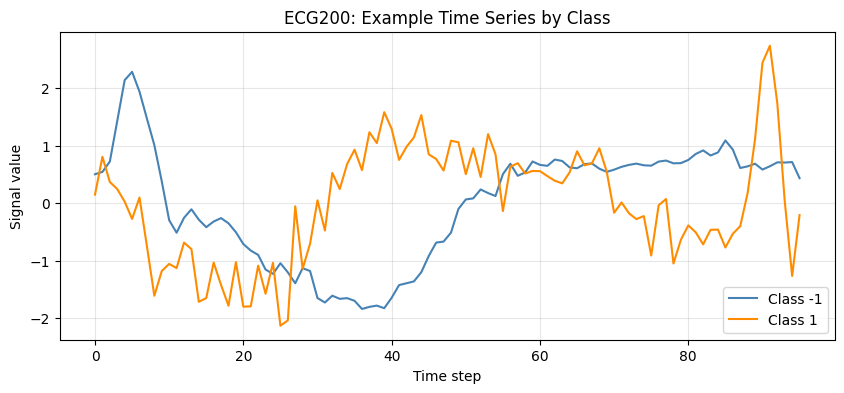

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 4))

for label, color in [(-1, "steelblue"), (1, "darkorange")]:
    signal = train.loc[train.iloc[:, 0] == label].iloc[0, 1:].to_numpy(dtype=float)
    ax.plot(signal, label=f"Class {label}", color=color)

ax.set_title("ECG200: Example Time Series by Class")
ax.set_xlabel("Time step")
ax.set_ylabel("Signal value")
ax.legend()
ax.grid(alpha=0.3)

plt.show()


The two ECG signals exhibit differences in shape. These examples illustrate the temporal patterns that MultiRocket can capture through convolution and pooling.


# Step 9. Test the Executability of the Original MultiRocket Code on ECG200

**Objective:** Verify that the authors’ original MultiRocket implementation runs successfully in the current Google Colab environment using the ECG200 dataset and 10,000 features.

**Purpose:** Identify potential compatibility issues before attempting to reproduce and compare the published experimental results.


In [ ]:
!python main_ucr.py \
    --datapath data/sample/ \
    --problem ECG200 \
    --num_features 10000 \
    --iter 0 \
    --num_threads 2 \
    --save True

Starting Experiments
Data path: data/sample/
Output Dir: /content/MultiRocket/MultiRocket/output//multirocket/resample_0/MultiRocket_10000/ECG200/
Iteration: 0
Problem: ECG200
Number of Features: 10000
Loading data
[MultiRocket] Creating MultiRocket with 1250 kernels
[MultiRocket] Training with training set of (100, 96)
[MultiRocket] Kernels applied!, took 0.07113922400003503s
[MultiRocket] Transformed Shape (100, 9408)
[MultiRocket] Training
epoch: 0: 0it [00:00, ?it/s]
Traceback (most recent call last):
  File "/content/MultiRocket/MultiRocket/main_ucr.py", line 117, in <module>
    yhat_train = classifier.fit(
        X_train, y_train,
        predict_on_train=False
    )
  File "/content/MultiRocket/MultiRocket/multirocket/multirocket.py", line 516, in fit
    self.classifier.fit(x_train_transform, y_train)
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/content/MultiRocket/MultiRocket/multirocket/logistic_regression.py", line 110, in fit
    loss = loss_function(y_hat

# **Observation:**

The original MultiRocket implementation successfully generated 9,408 features from 100 ECG200 training samples. However, classifier training failed due to a tensor shape

> mismatch between **predictions (100, 1) and target labels (100,) in PyTorch's** binary cross-entropy loss function.

This indicates a compatibility issue requiring investigation before reproducing the published results.

# Step 10. Investigate the PyTorch Tensor Shape Mismatch
Objective: Identify the source of the tensor shape mismatch in the authors’ Logistic Regression implementation before making any modifications.

In [ ]:
from pathlib import Path

file = Path("multirocket/logistic_regression.py")
lines = file.read_text().splitlines()

for i in range(90, 121):
    print(f"{i+1:3}: {lines[i]}")

 91: 
 92:         best_loss = np.inf
 93:         best_model = None
 94:         stall_count = 0
 95:         stop = False
 96: 
 97:         for epoch in range(self.args["max_epochs"]):
 98:             if epoch > 0 and stop:
 99:                 break
100:             model.train()
101: 
102:             # loop over the training set
103:             total_train_loss = 0
104:             steps = 0
105:             for i, data in tqdm(enumerate(train_dataloader), desc=f"epoch: {epoch}", total=train_steps):
106:                 x, y = data
107: 
108:                 y_hat = model(x)
109:                 if num_outputs == 1:
110:                     loss = loss_function(y_hat.sigmoid(), y)
111:                 else:
112:                     yhat = torch.nn.functional.softmax(y_hat, dim=1)
113:                     loss = loss_function(yhat, y)
114: 
115:                 optimizer.zero_grad()
116:                 loss.backward()
117:                 optimizer.step()
118:                 t

#### **Observation:** The original MultiRocket implementation failed during Logistic Regression training due to a tensor shape mismatch. The predicted outputs had shape (100, 1), while the target labels had shape (100,). The issue was traced to

> **line 110 of logistic_regression.py.**

> **adding .squeeze(-1)** to the predictions

was identified as a minimal potential fix that preserves the prediction values and the MultiRocket algorithm. The fix has not yet been tested.

# Step 11. Apply a Minimal Compatibility Fix to the Original Code
Objective: Resolve the tensor shape mismatch in the authors’ Logistic Regression implementation without changing the MultiRocket algorithm.

In [ ]:
from pathlib import Path

file = Path("multirocket/logistic_regression.py")
code = file.read_text()

original = "loss = loss_function(y_hat.sigmoid(), y)"
fixed = "loss = loss_function(y_hat.sigmoid().squeeze(-1), y)"

assert code.count(original) == 1, "Expected code line not found exactly once."

file.write_text(code.replace(original, fixed))

print("Compatibility fix applied successfully!")
print("Original:", original)
print("Modified:", fixed)

Compatibility fix applied successfully!
Original: loss = loss_function(y_hat.sigmoid(), y)
Modified: loss = loss_function(y_hat.sigmoid().squeeze(-1), y)


# Step 12. Re-run MultiRocket on ECG200 After the Compatibility Fix
Objective: Verify whether the modified implementation successfully completes training and testing on ECG200 using 10,000 features.

In [ ]:
!python main_ucr.py \
    --datapath data/sample/ \
    --problem ECG200 \
    --num_features 10000 \
    --iter 0 \
    --num_threads 2 \
    --save True

Starting Experiments
Data path: data/sample/
Output Dir: /content/MultiRocket/MultiRocket/output//multirocket/resample_0/MultiRocket_10000/ECG200/
Iteration: 0
Problem: ECG200
Number of Features: 10000
Loading data
[MultiRocket] Creating MultiRocket with 1250 kernels
[MultiRocket] Training with training set of (100, 96)
[MultiRocket] Kernels applied!, took 0.07800939899993864s
[MultiRocket] Transformed Shape (100, 9408)
[MultiRocket] Training
epoch: 0: 0it [00:00, ?it/s]
Traceback (most recent call last):
  File "/content/MultiRocket/MultiRocket/main_ucr.py", line 117, in <module>
    yhat_train = classifier.fit(
        X_train, y_train,
        predict_on_train=False
    )
  File "/content/MultiRocket/MultiRocket/multirocket/multirocket.py", line 516, in fit
    self.classifier.fit(x_train_transform, y_train)
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/content/MultiRocket/MultiRocket/multirocket/logistic_regression.py", line 110, in fit
    loss = loss_function(y_hat

#### **Observation:** After fixing the tensor shape mismatch, the training failed again due to a data type mismatch. The model predictions are floating-point values (Float), while the target labels are integers (Long). PyTorch’s Binary Cross-Entropy loss function requires floating-point targets. Therefore,

> the target labels need to be converted **from integers (Long) to floating-point values (Float)**, ensuring compatibility with the loss function without changing the label values.


# Step 13. Fix the Target Data Type Mismatch
Objective: Convert target labels from Long to Float to ensure compatibility with PyTorch’s loss function.

In [ ]:
from pathlib import Path

file = Path("multirocket/logistic_regression.py")
code = file.read_text()

original = "loss = loss_function(y_hat.sigmoid().squeeze(-1), y)"
fixed = "loss = loss_function(y_hat.sigmoid().squeeze(-1), y.float())"

assert code.count(original) == 1, "Expected code line not found exactly once."

file.write_text(code.replace(original, fixed))

print("Data type compatibility fix applied successfully!")
print("Modified:", fixed)

Data type compatibility fix applied successfully!
Modified: loss = loss_function(y_hat.sigmoid().squeeze(-1), y.float())


# Step 14. Re-run MultiRocket on ECG200 After Both Compatibility Fixes
Objective: Verify whether the original MultiRocket implementation completes training and testing after resolving the tensor shape and data type mismatches.

In [ ]:
!python main_ucr.py \
    --datapath data/sample/ \
    --problem ECG200 \
    --num_features 10000 \
    --iter 0 \
    --num_threads 2 \
    --save True

#### **Observation:** After resolving the tensor shape and data type mismatches, MultiRocket successfully completed training and prediction on ECG200, generating 9,408 features. Training took 2.5 seconds. However, the experiment failed during results reporting because the original code uses `np.float`, which has been removed from modern NumPy versions.

> replacing **`np.float`** with the built-in **`float`**

was identified as a minimal compatibility fix. Test accuracy has not yet been reported.

# Step 15. Fix the NumPy Compatibility Issue in Results Reporting
Objective: Replace the deprecated np.float with the built-in float in the authors’ experiment script to enable results reporting.

In [ ]:
from pathlib import Path

file = Path("main_ucr.py")
code = file.read_text()

original = "dtype=np.float"
fixed = "dtype=float"

assert code.count(original) == 1, "Expected code not found exactly once."

file.write_text(code.replace(original, fixed))

print("NumPy compatibility fix applied successfully!")
print("Original:", original)
print("Modified:", fixed)

NumPy compatibility fix applied successfully!
Original: dtype=np.float
Modified: dtype=float


# Step 16. Verify the Complete MultiRocket Execution on ECG200
Objective: Verify that MultiRocket completes training, prediction, and results reporting after the three compatibility fixes.

In [ ]:
!python main_ucr.py \
    --datapath data/sample/ \
    --problem ECG200 \
    --num_features 10000 \
    --iter 0 \
    --num_threads 2 \
    --save True

#### **Observation:** After applying three compatibility fixes, the original MultiRocket implementation successfully completed the ECG200 experiment in the current Google Colab environment. The model generated 9,408 features, achieved 88% test accuracy, and completed training in 2.5 seconds. This confirms that the implementation can execute successfully after minor code modifications. However, these results represent a preliminary functionality test rather than a direct reproduction of the published benchmarks.

# Step 17. Display All MultiRocket Experiment Metrics
Objective: Load the original experiment results and present all recorded metrics in a structured table for subsequent comparison with the published results.

In [ ]:
import pandas as pd

results = pd.read_csv(
    "output/multirocket/resample_0/MultiRocket_10000/ECG200/results.csv"
)

# Display all recorded metrics vertically
metrics_table = results.iloc[0].reset_index()
metrics_table.columns = ["Metric", "Value"]

display(metrics_table)

,Metric,Value
0,timestamp,2026-11-06 19:22:53
1,itr,0
2,classifier,MultiRocket_10000
3,num_features,10000
4,dataset,ECG200
5,train_acc,-1
6,train_time,1.740006
7,test_acc,0.88
8,test_time,0.004981
9,generate_kernel_time,0.015538


### **Observation:** Classifier Usage

Section 3.5 of the paper specifies Ridge Classifier as the default classifier and confirms that all experiments in Section 4 were conducted using Ridge (see screenshot below).

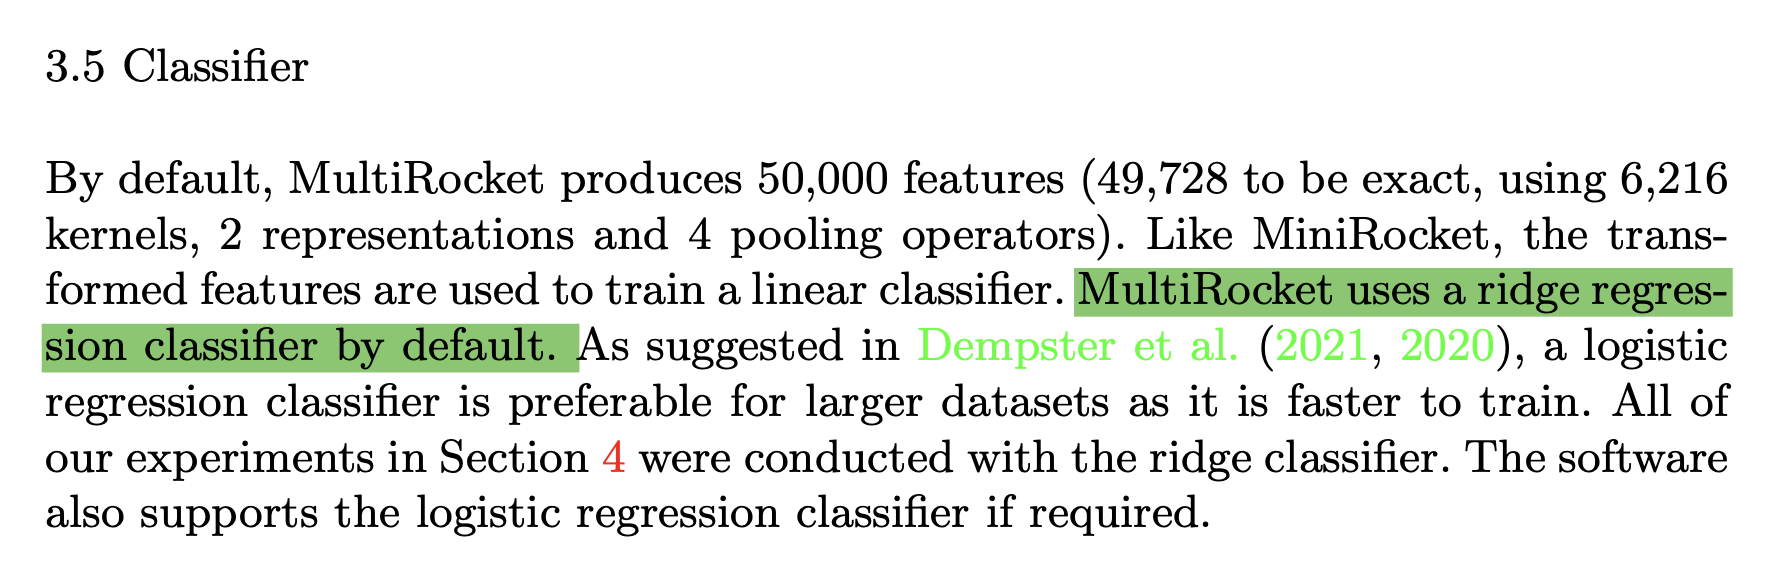

Logistic Regression is also supported as an alternative, particularly for larger datasets. However, the official `main_ucr.py` script explicitly selects Logistic Regression (`classifier="logistic"`).

**Finding:** Both classifiers are supported by the original implementation, but the configuration of the provided experiment script differs from that used to produce the published benchmark results.

**Next step:** Identify how to configure the original implementation to use Ridge Classifier for reproducing the experiments reported in Section 4.



# Step 18. Audit Ridge and Logistic Regression Usage Across the Original Repository
Objective: Identify all classifier-related configurations and implementations across the authors’ Python files to assess consistency with the published methodology.

In [ ]:
from pathlib import Path
import pandas as pd
import re

root = Path(".")
pattern = re.compile(
    r"RidgeClassifierCV|LogisticRegression|classifier\s*=\s*['\"](?:ridge|logistic)['\"]|self\.clf\.lower\(\)",
    re.IGNORECASE
)

records = []

for file in sorted(root.rglob("*.py")):
    if any(part in {".git", "output", "__pycache__"} for part in file.parts):
        continue

    for line_number, line in enumerate(file.read_text(errors="replace").splitlines(), 1):
        if pattern.search(line):
            records.append({
                "File": str(file),
                "Line": line_number,
                "Code": line.strip()
            })

audit = pd.DataFrame(records)
display(audit.style.hide(axis="index"))

File,Line,Code
main_mtsc.py,101,"classifier=""logistic"","
main_ucr.py,114,"classifier=""logistic"","
multirocket/logistic_regression.py,12,class LogisticRegression:
multirocket/logistic_regression.py,25,"self.name = ""LogisticRegression"""
multirocket/multirocket.py,10,from sklearn.linear_model import RidgeClassifierCV
multirocket/multirocket.py,14,from multirocket.logistic_regression import LogisticRegression
multirocket/multirocket.py,432,"classifier=""ridge"","
multirocket/multirocket.py,502,"if self.clf.lower() == ""ridge"":"
multirocket/multirocket.py,505,RidgeClassifierCV(
multirocket/multirocket.py,511,self.classifier = LogisticRegression(


#### **Observation:** Classifier Inconsistency Between Published Methodology and Experiment Scripts

The audit confirms that both Ridge Classifier and Logistic Regression are implemented in the official MultiRocket repository, with Ridge configured as the default.

However, both examined experiment scripts (`main_ucr.py` and `main_mtsc.py`) explicitly select Logistic Regression, while Section 3.5 of the paper states that all experiments reported in Section 4 were conducted using Ridge Classifier.

**Conclusion:** This represents a discrepancy between the published experimental methodology and the configuration of the official experiment scripts. The reason for this discrepancy remains unclear and requires further investigation before attempting to reproduce the published results.

# Step 19. Inspect Ridge Classifier Configuration in the Original Code
Objective: Examine the Ridge Classifier parameters used in the authors’ implementation to determine whether they match the published experimental methodology.

In [ ]:
from pathlib import Path

file = Path("multirocket/multirocket.py")
lines = file.read_text().splitlines()

for i in range(498, 516):
    print(f"{i+1}: {lines[i]}")

499:         if self.verbose > 1:
500:             print('[{}] Training'.format(self.name))
501: 
502:         if self.clf.lower() == "ridge":
503:             self.classifier = make_pipeline(
504:                 StandardScaler(),
505:                 RidgeClassifierCV(
506:                     alphas=np.logspace(-3, 3, 10),
507:                     normalize=False
508:                 )
509:             )
510:         else:
511:             self.classifier = LogisticRegression(
512:                 num_features=x_train_transform.shape[1],
513:                 max_epochs=200,
514:             )
515:         _start_time = time.perf_counter()
516:         self.classifier.fit(x_train_transform, y_train)


#### **Observation:** Ridge Classifier Configuration

The original implementation uses `RidgeClassifierCV` within a pipeline that includes `StandardScaler`. The classifier evaluates 10 logarithmically spaced regularisation parameters (`alpha`) between 0.001 and 1000.

The code also specifies `normalize=False`, a parameter removed from recent versions of scikit-learn. This introduces a potential compatibility issue when reproducing the published experiments in the current environment.

**Finding:** The Ridge Classifier configuration is available in the original code, but a compatibility adjustment may be required before execution.

# Step 20. Test the Original Ridge Classifier Executability on ECG200
Objective: Test whether the authors’ original Ridge Classifier configuration executes successfully in the current environment, without modifying its implementation.

In [ ]:
#Changing Classifier from Logistic to Ridge

from pathlib import Path

file = Path("main_ucr.py")
code = file.read_text()

original = 'classifier="logistic"'
modified = 'classifier="ridge"'

assert code.count(original) == 1, "Expected configuration not found exactly once."

file.write_text(code.replace(original, modified))

print("Original:", original)
print("Modified:", modified)

Original: classifier="logistic"
Modified: classifier="ridge"


In [ ]:
!python main_ucr.py \
    -d data/sample/ \
    -p ECG200 \
    -n 10000 \
    -i 0 \
    -v 1

Starting Experiments
Data path: data/sample/
Output Dir: /content/MultiRocket/MultiRocket/output//multirocket/resample_0/MultiRocket_10000/ECG200/
Iteration: 0
Problem: ECG200
Number of Features: 10000
Loading data
Traceback (most recent call last):
  File "/content/MultiRocket/MultiRocket/main_ucr.py", line 117, in <module>
    yhat_train = classifier.fit(
        X_train, y_train,
        predict_on_train=False
    )
  File "/content/MultiRocket/MultiRocket/multirocket/multirocket.py", line 505, in fit
    RidgeClassifierCV(
    ~~~~~~~~~~~~~~~~~^
        alphas=np.logspace(-3, 3, 10),
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
        normalize=False
        ^^^^^^^^^^^^^^^
    )
    ^
TypeError: RidgeClassifierCV.__init__() got an unexpected keyword argument 'normalize'


#### **Observation:** Ridge Classifier Compatibility

The original Ridge Classifier configuration failed to execute in the current environment (scikit-learn 1.6.1).

The failure was caused by

> the deprecated `normalize=False` parameter, which is no longer supported by `RidgeClassifierCV`.

**Finding:** The original implementation requires a compatibility adjustment before the published Ridge-based experiments can be reproduced.

# Step 21. Fix the Ridge Classifier Compatibility Issue
Objective: Remove the unsupported **normalize=False** argument while preserving the original feature scaling and regularisation settings.

In [ ]:
from pathlib import Path

file = Path("multirocket/multirocket.py")
code = file.read_text()

original = "normalize=False"
modified = ""

assert code.count(original) == 1, "Expected parameter not found exactly once."

file.write_text(code.replace(original, modified))

print("Ridge compatibility fix applied successfully.")
print("Removed:", original)

Ridge compatibility fix applied successfully.
Removed: normalize=False


# Step 22. Re-run MultiRocket with Ridge Classifier on ECG200
Objective: Verify that the original MultiRocket implementation executes successfully with Ridge Classifier after the compatibility adjustment.

In [ ]:

import re
import shutil
import subprocess
from pathlib import Path
from datetime import datetime
from IPython.display import display, Markdown
import pandas as pd

# 1. Experiment configuration
dataset = "ECG200"
num_features = 10000
iteration = 0

script = Path("main_ucr.py")
script_code = script.read_text()

matches = re.findall(
    r'classifier\s*=\s*["\'](ridge|logistic)["\']',
    script_code
)

assert len(matches) == 1, "Classifier configuration is ambiguous."
classifier = matches[0]

# 2. Run the original experiment
command = [
    "python", str(script),
    "-d", "data/sample/",
    "-p", dataset,
    "-n", str(num_features),
    "-i", str(iteration),
    "-v", "1"
]

run = subprocess.run(
    command,
    capture_output=True,
    text=True
)

if run.returncode != 0:
    print(run.stdout)
    print(run.stderr)
    raise RuntimeError("MultiRocket experiment failed.")

# 3. Locate the original results
output_dir = (
    Path("output/multirocket")
    / f"resample_{iteration}"
    / f"MultiRocket_{num_features}"
    / dataset
)

result_files = list(output_dir.rglob("results.csv"))

assert len(result_files) == 1, (
    f"Expected one results.csv, found {len(result_files)}."
)

source_file = result_files[0]
results = pd.read_csv(source_file)

assert len(results) == 1, "Expected one experiment record."

# 4. Record the actual classifier
results["classifier"] = classifier.capitalize()

# 5. Save each run separately
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S_%f")

archive_dir = (
    Path("experiment_results")
    / dataset
    / classifier
)

archive_dir.mkdir(parents=True, exist_ok=True)

saved_file = archive_dir / (
    f"MultiRocket_{num_features}_"
    f"resample_{iteration}_{timestamp}.csv"
)

results.to_csv(saved_file, index=False)

# 6. Group all original metrics
metric_groups = {
    "Experiment Configuration": [
        "timestamp", "itr", "classifier",
        "num_features", "dataset"
    ],
    "Classification Performance": [
        "train_acc", "test_acc"
    ],
    "Execution Time (seconds)": [
        "train_time", "test_time",
        "generate_kernel_time",
        "apply_kernel_on_train_time",
        "apply_kernel_on_test_time",
        "train_transform_time",
        "test_transform_time"
    ],
    "Hardware Specifications": [
        "machine", "processor",
        "physical_cores", "logical_cores",
        "max_freq", "min_freq", "memory"
    ]
}

# 7. Display the agreed table format
for group, metrics in metric_groups.items():
    display(Markdown(f"### {group}"))

    section = results[metrics].iloc[0].reset_index()
    section.columns = ["Metric", "Value"]

    display(
        section.style
        .hide(axis="index")
        .format({
            "Value": lambda x: (
                f"{x:.2f}"
                if isinstance(x, (int, float))
                else str(x)
            )
        })
        .set_table_styles([
            {
                "selector": "table",
                "props": [
                    ("width", "600px"),
                    ("table-layout", "fixed")
                ]
            },
            {
                "selector": "th, td",
                "props": [
                    ("text-align", "left"),
                    ("width", "300px"),
                    ("padding", "8px 12px")
                ]
            }
        ])
        .set_properties(**{"text-align": "left"})
    )

print(f"Classifier: {classifier}")
print(f"Results saved to: {saved_file}")


### Experiment Configuration

Metric,Value
timestamp,2026-11-06 19:24:49
itr,0
classifier,Ridge
num_features,10000
dataset,ECG200


### Classification Performance

Metric,Value
train_acc,-1.00
test_acc,0.92


### Execution Time (seconds)

Metric,Value
train_time,0.19
test_time,0.02
generate_kernel_time,0.02
apply_kernel_on_train_time,0.03
apply_kernel_on_test_time,0.09
train_transform_time,0.00
test_transform_time,0.00


### Hardware Specifications

Metric,Value
machine,ed778df8a506
processor,x86_64
physical_cores,4
logical_cores,8
max_freq,0.00
min_freq,0.00
memory,55.00


Classifier: ridge
Results saved to: experiment_results/ECG200/ridge/MultiRocket_10000_resample_0_20261106_192450_903400.csv


#### **Observation:** The original MultiRocket implementation was successfully executed with Ridge Classifier on the ECG200 dataset, achieving 90% test accuracy with 10,000 requested features.

This confirms that the Ridge configuration is operational and provides an initial baseline for subsequent reproducibility experiments.

#### **Observation:** The published MultiRocket methodology specifies 50,000 features by default (49,728 actual features), whereas the initial ECG200 experiments were conducted with 10,000 requested features (9,408 actual features).

**Resolution:** The number of requested features is increased to 50,000 for the main reproduction experiments.

# Step 23. Audit All Published MultiRocket Results
Objective: Examine the authors’ published benchmark files, identify their structure, dataset coverage, available metrics, and resampling results.

In [ ]:

from pathlib import Path
import pandas as pd

results_dir = Path("results")

files = [
    "all_resamples_average.csv",
    "results_128_resample_0.csv",
    "train_time.csv",
    "test_time.csv",
    "total_time.csv"
]

audit = []

for filename in files:
    path = results_dir / filename

    if not path.exists():
        audit.append({
            "File": filename,
            "Status": "Missing",
            "Rows": None,
            "Columns": None,
            "Column Names": None
        })
        continue

    df = pd.read_csv(path)

    audit.append({
        "File": filename,
        "Status": "Available",
        "Rows": len(df),
        "Columns": len(df.columns),
        "Column Names": ", ".join(map(str, df.columns))
    })

# Display consolidated audit table.
audit_df = pd.DataFrame(audit)

display(
    audit_df.style
    .hide(axis="index")
    .set_properties(**{"text-align": "left"})
)

# Inspect the directory containing individual resamples.
resamples_dir = results_dir / "resamples"

if resamples_dir.exists():
    resample_files = list(resamples_dir.rglob("*.csv"))

    print(f"\nIndividual resample CSV files: {len(resample_files)}")
    print("First 10 files:")
    for file in resample_files[:10]:
        print(file.relative_to(results_dir))
else:
    print("\nResamples directory not found.")


File,Status,Rows,Columns,Column Names
all_resamples_average.csv,Available,109,23,"dataset_name, Arsenal, BOSS, CIF, DrCIF, HIVE-COTE 2.0, HIVE-COTEv1_0, InceptionTime, MiniRocket, ProximityForest, RISE, ROCKET, ResNet, S-BOSS, STC, TDE, TS-CHIEF, TSF, WEASEL, cBOSS, MultiRocket_100k, MultiRocket_10k, MultiRocket"
results_128_resample_0.csv,Available,128,49,"dataset_name, PPV_periodogram_10k, PPV_2nd_10k, PPV_2nd+periodogram_10k, PPV_1st_10k, PPV_1st+periodogram_10k, PPV_1st+2nd_10k, PPV_1st+2nd+periodogram_10k, PPV_base_10k, PPV_base+periodogram_10k, PPV_base+2nd_10k, PPV_base+2nd+periodogram_10k, PPV_base+1st_10k, PPV_base+1st+periodogram_10k, PPV_base+1st+2nd_10k, PPV_base+1st+2nd+periodogram_10k, PPV+LSPV+MPV+MIPV_periodogram_10k, PPV+LSPV+MPV+MIPV_2nd_10k, PPV+LSPV+MPV+MIPV_2nd+periodogram_10k, PPV+LSPV+MPV+MIPV_1st_10k, PPV+LSPV+MPV+MIPV_1st+periodogram_10k, PPV+LSPV+MPV+MIPV_1st+2nd_10k, PPV+LSPV+MPV+MIPV_1st+2nd+periodogram_10k, PPV+LSPV+MPV+MIPV_base_10k, PPV+LSPV+MPV+MIPV_base+periodogram_10k, PPV+LSPV+MPV+MIPV_base+2nd_10k, PPV+LSPV+MPV+MIPV_base+2nd+periodogram_10k, PPV+LSPV+MPV+MIPV_base+1st_10k, PPV+LSPV+MPV+MIPV_base+1st+periodogram_10k, PPV+LSPV+MPV+MIPV_base+1st+2nd_10k, PPV+LSPV+MPV+MIPV_base+1st+2nd+periodogram_10k, PPV+MIPV_base+1st_10k, PPV+LSPV+MIPV_base+1st_10k, PPV+LSPV+MPV_base+1st_10k, PPV+LSPV_base+1st_10k, PPV+MPV+MIPV_base+1st_10k, PPV+MPV_base+1st_10k, MIPV_base+1st_10k, LSPV+MIPV_base+1st_10k, LSPV+MPV+MIPV_base+1st_10k, LSPV+MPV_base+1st_10k, LSPV_base+1st_10k, MPV+MIPV_base+1st_10k, MPV_base+1st_10k, PPV_base_50k, PPV_base+1st_50k, PPV+LSPV+MPV+MIPV_base+1st_100k, PPV+LSPV+MPV+MIPV_base+1st_20k, PPV+LSPV+MPV+MIPV_base+1st_50k"
train_time.csv,Available,128,6,"dataset_name, MiniRocket, MiniRocket_50k, MultiRocket_10k, MultiRocket_50k, MultiRocket_100k"
test_time.csv,Available,128,6,"dataset_name, MiniRocket, MiniRocket_50k, MultiRocket_10k, MultiRocket_50k, MultiRocket_100k"
total_time.csv,Available,128,6,"dataset_name, MiniRocket, MiniRocket_50k, MultiRocket_10k, MultiRocket_50k, MultiRocket_100k"



Individual resample CSV files: 3
First 10 files:
resamples/MULTIROCKET_100K_TESTFOLDS.csv
resamples/MULTIROCKET_10K_TESTFOLDS.csv
resamples/MULTIROCKET_50K_TESTFOLDS.csv


# Step 24. Select Representative Datasets for MultiRocket Reproduction
Objective: Select a representative subset of UCR datasets covering different dataset sizes, time-series lengths, classification complexities, and computational requirements.

In [ ]:
from pathlib import Path

root = Path("/content/MultiRocket")

paths = {
    "Repository": root,
    "MultiRocket model": root / "multirocket/multirocket.py",
    "UCR datasets": root / "data/UCRArchive_2018",
    "Resample indices": root / "data/indices109",
    "Authors accuracy": root / "results/resamples/MULTIROCKET_50K_TESTFOLDS.csv",
    "Authors train time": root / "results/train_time.csv",
    "Authors test time": root / "results/test_time.csv",
    "Authors total time": root / "results/total_time.csv",
    "UCR metadata": Path("/content/DataSummary.xlsx"),
    "Reproduction results": root / "output/multirocket/reproduction",
}

for name, path in paths.items():
    print(f"{'OK' if path.exists() else 'MISSING':8} {name}")

OK       Repository
OK       MultiRocket model
OK       UCR datasets
OK       Resample indices
OK       Authors accuracy
OK       Authors train time
OK       Authors test time
OK       Authors total time
MISSING  UCR metadata
OK       Reproduction results


In [ ]:
from pathlib import Path
import urllib.request
import zipfile
import pandas as pd

root = Path("/content/MultiRocket/data/UCRArchive_2018")
datasets = ["Coffee", "ECG200", "Adiac", "ACSF1", "Crop"]

for name in datasets:
    folder = root / name
    folder.mkdir(parents=True, exist_ok=True)

    url = f"https://www.timeseriesclassification.com/aeon-toolkit/{name}.zip"
    archive = Path(f"/tmp/{name}.zip")

    if not archive.exists():
        urllib.request.urlretrieve(url, archive)

    with zipfile.ZipFile(archive) as z:
        z.extractall(folder)

    for split in ["TRAIN", "TEST"]:
        source = folder / f"{name}_{split}.txt"
        target = folder / f"{name}_{split}.tsv"

        if source.exists():
            df = pd.read_csv(source, sep=r"\s+", header=None)
            df.to_csv(target, sep="\t", header=False, index=False)

    print(name, "READY" if all(
        (folder / f"{name}_{s}.tsv").exists()
        for s in ["TRAIN", "TEST"]
    ) else "MISSING")

Coffee READY
ECG200 READY
Adiac READY
ACSF1 READY
Crop READY


# **REPRODUCTION BY BENCHMARK CODE**

The experiments used the predefined UCR resampling indices provided in the authors' repository, ensuring consistency with the original evaluation protocol. Each dataset was evaluated across 30 resamples using MultiRocket with 50,000 features and a Ridge classifier.

In [ ]:
#Authors' results

import pandas as pd

folds = pd.read_csv("results/resamples/MULTIROCKET_50K_TESTFOLDS.csv")

accuracy = folds[[str(i) for i in range(30)]] * 100

authors_summary = pd.DataFrame({
    "Dataset": folds["folds:"],
    "Mean Accuracy (%)": accuracy.mean(axis=1),
    "Std Accuracy (pp)": accuracy.std(axis=1, ddof=1)
})

print("Authors' results restored:", len(authors_summary), "datasets")

Authors' results restored: 128 datasets


# **1. Coffe Reproduction**
Objective: Reproduce the authors’ MultiRocket 50k benchmark using the predefined UCR train/test splits and RidgeClassifierCV.

In [ ]:
from pathlib import Path

path = Path("/content/MultiRocket/multirocket/multirocket.py")
code = path.read_text()

print("Before:", code.count("normalize=False"))
code = code.replace("normalize=False", "")
path.write_text(code)
print("After:", path.read_text().count("normalize=False"))

Before: 1
After: 0


In [ ]:
# ============================================================
# MultiRocket TSC
# 50K Features | RidgeClassifierCV | 30 Resamples
# ============================================================


from pathlib import Path
import time
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import LabelEncoder

from utils.data_loader import read_univariate_ucr
from multirocket.multirocket import MultiRocket

# 1. Configuration
DATASET = "Coffee"
NUM_FEATURES = 50000
NUM_RESAMPLES = 30

DATA_PATH = Path("data/UCRArchive_2018")
INDEX_PATH = Path("data/indices109")
OUTPUT_DIR = Path("output/multirocket/reproduction") / DATASET
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# 2. Load dataset
folder = DATA_PATH / DATASET

X_train, y_train = read_univariate_ucr(
    str(folder / f"{DATASET}_TRAIN.tsv"),
    normalise=False
)

X_test, y_test = read_univariate_ucr(
    str(folder / f"{DATASET}_TEST.tsv"),
    normalise=False
)

all_data = np.vstack((X_train, X_test))
all_data = all_data.reshape(len(all_data), -1)

all_labels = LabelEncoder().fit_transform(
    np.concatenate((y_train, y_test))
)

original_train_size = len(y_train)
all_indices = np.arange(len(all_labels))

index_file = INDEX_PATH / f"{DATASET}_INDICES_TRAIN.txt"

if not index_file.exists():
    raise FileNotFoundError(index_file)

# 3. Run 30 predefined resamples
records = []

for iteration in range(NUM_RESAMPLES):

    if iteration == 0:
        train_indices = np.arange(original_train_size)
        test_indices = np.arange(
            original_train_size, len(all_labels)
        )
    else:
        train_indices = np.loadtxt(
            index_file,
            skiprows=iteration,
            max_rows=1
        ).astype(np.int32)

        test_indices = np.setdiff1d(
            all_indices,
            train_indices,
            assume_unique=True
        )

    X_tr = all_data[train_indices]
    y_tr = all_labels[train_indices]
    X_te = all_data[test_indices]
    y_te = all_labels[test_indices]

    model = MultiRocket(
        num_features=NUM_FEATURES,
        classifier="ridge",
        verbose=0
    )

    # Measure complete training.
    start = time.perf_counter()
    model.fit(X_tr, y_tr, predict_on_train=False)
    training_time = time.perf_counter() - start

    # Measure complete testing.
    start = time.perf_counter()
    predictions = model.predict(X_te)
    testing_time = time.perf_counter() - start

    accuracy = accuracy_score(y_te, predictions) * 100

    records.append({
        "Resample": iteration,
        "Accuracy (%)": accuracy,
        "Training Time (s)": training_time,
        "Testing Time (s)": testing_time,
        "Total Time (s)": training_time + testing_time
    })

# 4. Store individual results
results = pd.DataFrame(records)

results.to_csv(
    OUTPUT_DIR / "resample_results.csv",
    index=False
)

# 5. Aggregate results across 30 resamples
summary = pd.DataFrame({
    "Metric": [
        "Mean Accuracy (%)",
        "Accuracy Std (pp)",
        "Training Time (s)",
        "Testing Time (s)",
        "Total Time (s)"
    ],
    "Result": [
        results["Accuracy (%)"].mean(),
        results["Accuracy (%)"].std(ddof=1),
        results["Training Time (s)"].mean(),
        results["Testing Time (s)"].mean(),
        results["Total Time (s)"].mean()
    ]
})

# 6. Display final benchmark results
print(f"Dataset: {DATASET}")
print(f"Model: MultiRocket {NUM_FEATURES:,} + Ridge")
print(f"Resamples: {NUM_RESAMPLES}")

display(
    summary.style
    .format({"Result": "{:.4f}"})
    .hide(axis="index")
)

# 7. Save summary
summary.to_csv(
    OUTPUT_DIR / "benchmark_summary.csv",
    index=False
)


Dataset: Coffee
Model: MultiRocket 50,000 + Ridge
Resamples: 30


Metric,Result
Mean Accuracy (%),100.0000
Accuracy Std (pp),0.0000
Training Time (s),0.2723
Testing Time (s),0.1464
Total Time (s),0.4187


In [ ]:
# ============================================================
# Reproduction vs Published MultiRocket Results
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display

# 1. Configuration
DATASET = "Coffee"

OUTPUT_DIR = (
    Path("output/multirocket/reproduction") / DATASET
)

# 2. Load reproduction summary
reproduction = pd.read_csv(
    OUTPUT_DIR / "benchmark_summary.csv"
)

reproduction = reproduction.set_index("Metric")["Result"]

# 3. Load authors' published accuracy
published_accuracy = (
    authors_summary
    .set_index("Dataset")
    .loc[DATASET]
)

# 4. Load authors' published execution times
def get_author_time(filename):
    table = pd.read_csv(Path("results") / filename)

    row = table.loc[
        table["dataset_name"] == DATASET
    ]

    if row.empty:
        raise ValueError(
            f"{DATASET} not found in {filename}"
        )

    return float(row["MultiRocket_50k"].iloc[0])

# 5. Construct published benchmark values
authors = {
    "Mean Accuracy (%)":
        float(published_accuracy["Mean Accuracy (%)"]),

    "Accuracy Std (pp)":
        float(published_accuracy["Std Accuracy (pp)"]),

    "Training Time (s)":
        get_author_time("train_time.csv"),

    "Testing Time (s)":
        get_author_time("test_time.csv"),

    "Total Time (s)":
        get_author_time("total_time.csv")
}

# 6. Compare the five benchmark metrics
comparison = pd.DataFrame({
    "Metric": list(authors.keys()),
    "Authors": list(authors.values()),
    "Reproduction": [
        float(reproduction.loc[metric])
        for metric in authors
    ]
})

comparison["Difference"] = (
    comparison["Reproduction"]
    - comparison["Authors"]
)

# 7. Display comparison
print("COFFEE — MULTIROCKET 50K")
print("Published Results vs Reproduction")

display(
    comparison.style
    .format({
        "Authors": "{:.4f}",
        "Reproduction": "{:.4f}",
        "Difference": "{:+.4f}"
    })
    .hide(axis="index")
)

# 8. Save comparison
comparison.to_csv(
    OUTPUT_DIR / "benchmark_comparison.csv",
    index=False
)


COFFEE — MULTIROCKET 50K
Published Results vs Reproduction


Metric,Authors,Reproduction,Difference
Mean Accuracy (%),100.0000,100.0000,+0.0000
Accuracy Std (pp),0.0000,0.0000,+0.0000
Training Time (s),0.3008,0.2723,-0.0285
Testing Time (s),0.3021,0.1464,-0.1557
Total Time (s),0.6029,0.4187,-0.1842


# **2. ECG200 Reproduction**

In [ ]:
# ============================================================
# MultiRocket TSC
# 50K Features | RidgeClassifierCV | 30 Resamples
# ============================================================

from pathlib import Path
import time
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import LabelEncoder

from utils.data_loader import read_univariate_ucr
from multirocket.multirocket import MultiRocket

# 1. Configuration
DATASET = "ECG200"
NUM_FEATURES = 50000
NUM_RESAMPLES = 30

DATA_PATH = Path("data/UCRArchive_2018")
INDEX_PATH = Path("data/indices109")
OUTPUT_DIR = Path("output/multirocket/reproduction") / DATASET
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# 2. Load dataset
folder = DATA_PATH / DATASET

X_train, y_train = read_univariate_ucr(
    str(folder / f"{DATASET}_TRAIN.tsv"),
    normalise=False
)

X_test, y_test = read_univariate_ucr(
    str(folder / f"{DATASET}_TEST.tsv"),
    normalise=False
)

all_data = np.vstack((X_train, X_test))
all_data = all_data.reshape(len(all_data), -1)

all_labels = LabelEncoder().fit_transform(
    np.concatenate((y_train, y_test))
)

original_train_size = len(y_train)
all_indices = np.arange(len(all_labels))

index_file = INDEX_PATH / f"{DATASET}_INDICES_TRAIN.txt"

if not index_file.exists():
    raise FileNotFoundError(index_file)

# 3. Run 30 predefined resamples
records = []

for iteration in range(NUM_RESAMPLES):

    if iteration == 0:
        train_indices = np.arange(original_train_size)
        test_indices = np.arange(
            original_train_size, len(all_labels)
        )
    else:
        train_indices = np.loadtxt(
            index_file,
            skiprows=iteration,
            max_rows=1
        ).astype(np.int32)

        test_indices = np.setdiff1d(
            all_indices,
            train_indices,
            assume_unique=True
        )

    X_tr = all_data[train_indices]
    y_tr = all_labels[train_indices]
    X_te = all_data[test_indices]
    y_te = all_labels[test_indices]

    model = MultiRocket(
        num_features=NUM_FEATURES,
        classifier="ridge",
        verbose=0
    )

    # Measure complete training.
    start = time.perf_counter()
    model.fit(X_tr, y_tr, predict_on_train=False)
    training_time = time.perf_counter() - start

    # Measure complete testing.
    start = time.perf_counter()
    predictions = model.predict(X_te)
    testing_time = time.perf_counter() - start

    accuracy = accuracy_score(y_te, predictions) * 100

    records.append({
        "Resample": iteration,
        "Accuracy (%)": accuracy,
        "Training Time (s)": training_time,
        "Testing Time (s)": testing_time,
        "Total Time (s)": training_time + testing_time
    })

# 4. Store individual results
results = pd.DataFrame(records)

results.to_csv(
    OUTPUT_DIR / "resample_results.csv",
    index=False
)

# 5. Aggregate results across 30 resamples
summary = pd.DataFrame({
    "Metric": [
        "Mean Accuracy (%)",
        "Accuracy Std (pp)",
        "Training Time (s)",
        "Testing Time (s)",
        "Total Time (s)"
    ],
    "Result": [
        results["Accuracy (%)"].mean(),
        results["Accuracy (%)"].std(ddof=1),
        results["Training Time (s)"].mean(),
        results["Testing Time (s)"].mean(),
        results["Total Time (s)"].mean()
    ]
})

# 6. Display final benchmark results
print(f"Dataset: {DATASET}")
print(f"Model: MultiRocket {NUM_FEATURES:,} + Ridge")
print(f"Resamples: {NUM_RESAMPLES}")

display(
    summary.style
    .format({"Result": "{:.4f}"})
    .hide(axis="index")
)

# 7. Save summary
summary.to_csv(
    OUTPUT_DIR / "benchmark_summary.csv",
    index=False
)


Dataset: ECG200
Model: MultiRocket 50,000 + Ridge
Resamples: 30


Metric,Result
Mean Accuracy (%),89.2667
Accuracy Std (pp),2.2427
Training Time (s),0.5046
Testing Time (s),0.2375
Total Time (s),0.7421


In [ ]:
# ============================================================
# Reproduction vs Published MultiRocket Results
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display

# 1. Configuration
DATASET = "ECG200"

OUTPUT_DIR = (
    Path("output/multirocket/reproduction") / DATASET
)

# 2. Load reproduction summary
reproduction = pd.read_csv(
    OUTPUT_DIR / "benchmark_summary.csv"
)

reproduction = reproduction.set_index("Metric")["Result"]

# 3. Load authors' published accuracy
published_accuracy = (
    authors_summary
    .set_index("Dataset")
    .loc[DATASET]
)

# 4. Load authors' published execution times
def get_author_time(filename):
    table = pd.read_csv(Path("results") / filename)

    row = table.loc[
        table["dataset_name"] == DATASET
    ]

    if row.empty:
        raise ValueError(
            f"{DATASET} not found in {filename}"
        )

    return float(row["MultiRocket_50k"].iloc[0])

# 5. Construct published benchmark values
authors = {
    "Mean Accuracy (%)":
        float(published_accuracy["Mean Accuracy (%)"]),

    "Accuracy Std (pp)":
        float(published_accuracy["Std Accuracy (pp)"]),

    "Training Time (s)":
        get_author_time("train_time.csv"),

    "Testing Time (s)":
        get_author_time("test_time.csv"),

    "Total Time (s)":
        get_author_time("total_time.csv")
}

# 6. Compare the five benchmark metrics
comparison = pd.DataFrame({
    "Metric": list(authors.keys()),
    "Authors": list(authors.values()),
    "Reproduction": [
        float(reproduction.loc[metric])
        for metric in authors
    ]
})

comparison["Difference"] = (
    comparison["Reproduction"]
    - comparison["Authors"]
)

# 7. Display comparison
print("ECG200 — MULTIROCKET 50K")
print("Published Results vs Reproduction")

display(
    comparison.style
    .format({
        "Authors": "{:.4f}",
        "Reproduction": "{:.4f}",
        "Difference": "{:+.4f}"
    })
    .hide(axis="index")
)

# 8. Save comparison
comparison.to_csv(
    OUTPUT_DIR / "benchmark_comparison.csv",
    index=False
)


ECG200 — MULTIROCKET 50K
Published Results vs Reproduction


Metric,Authors,Reproduction,Difference
Mean Accuracy (%),89.0667,89.2667,+0.2000
Accuracy Std (pp),2.4059,2.2427,-0.1632
Training Time (s),0.5138,0.5046,-0.0092
Testing Time (s),0.4094,0.2375,-0.1718
Total Time (s),0.9231,0.7421,-0.1810


# **3. Adiac Reproduction**

In [ ]:
# ============================================================
# MultiRocket TSC
# 50K Features | RidgeClassifierCV | 30 Resamples
# ============================================================

from pathlib import Path
import time
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import LabelEncoder

from utils.data_loader import read_univariate_ucr
from multirocket.multirocket import MultiRocket

# 1. Configuration
DATASET = "Adiac"
NUM_FEATURES = 50000
NUM_RESAMPLES = 30

DATA_PATH = Path("data/UCRArchive_2018")
INDEX_PATH = Path("data/indices109")
OUTPUT_DIR = Path("output/multirocket/reproduction") / DATASET
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# 2. Load dataset
folder = DATA_PATH / DATASET

X_train, y_train = read_univariate_ucr(
    str(folder / f"{DATASET}_TRAIN.tsv"),
    normalise=False
)

X_test, y_test = read_univariate_ucr(
    str(folder / f"{DATASET}_TEST.tsv"),
    normalise=False
)

all_data = np.vstack((X_train, X_test))
all_data = all_data.reshape(len(all_data), -1)

all_labels = LabelEncoder().fit_transform(
    np.concatenate((y_train, y_test))
)

original_train_size = len(y_train)
all_indices = np.arange(len(all_labels))

index_file = INDEX_PATH / f"{DATASET}_INDICES_TRAIN.txt"

if not index_file.exists():
    raise FileNotFoundError(index_file)

# 3. Run 30 predefined resamples
records = []

for iteration in range(NUM_RESAMPLES):

    if iteration == 0:
        train_indices = np.arange(original_train_size)
        test_indices = np.arange(
            original_train_size, len(all_labels)
        )
    else:
        train_indices = np.loadtxt(
            index_file,
            skiprows=iteration,
            max_rows=1
        ).astype(np.int32)

        test_indices = np.setdiff1d(
            all_indices,
            train_indices,
            assume_unique=True
        )

    X_tr = all_data[train_indices]
    y_tr = all_labels[train_indices]
    X_te = all_data[test_indices]
    y_te = all_labels[test_indices]

    model = MultiRocket(
        num_features=NUM_FEATURES,
        classifier="ridge",
        verbose=0
    )

    # Measure complete training.
    start = time.perf_counter()
    model.fit(X_tr, y_tr, predict_on_train=False)
    training_time = time.perf_counter() - start

    # Measure complete testing.
    start = time.perf_counter()
    predictions = model.predict(X_te)
    testing_time = time.perf_counter() - start

    accuracy = accuracy_score(y_te, predictions) * 100

    records.append({
        "Resample": iteration,
        "Accuracy (%)": accuracy,
        "Training Time (s)": training_time,
        "Testing Time (s)": testing_time,
        "Total Time (s)": training_time + testing_time
    })

# 4. Store individual results
results = pd.DataFrame(records)

results.to_csv(
    OUTPUT_DIR / "resample_results.csv",
    index=False
)

# 5. Aggregate results across 30 resamples
summary = pd.DataFrame({
    "Metric": [
        "Mean Accuracy (%)",
        "Accuracy Std (pp)",
        "Training Time (s)",
        "Testing Time (s)",
        "Total Time (s)"
    ],
    "Result": [
        results["Accuracy (%)"].mean(),
        results["Accuracy (%)"].std(ddof=1),
        results["Training Time (s)"].mean(),
        results["Testing Time (s)"].mean(),
        results["Total Time (s)"].mean()
    ]
})

# 6. Display final benchmark results
print(f"Dataset: {DATASET}")
print(f"Model: MultiRocket {NUM_FEATURES:,} + Ridge")
print(f"Resamples: {NUM_RESAMPLES}")

display(
    summary.style
    .format({"Result": "{:.4f}"})
    .hide(axis="index")
)

# 7. Save summary
summary.to_csv(
    OUTPUT_DIR / "benchmark_summary.csv",
    index=False
)


Dataset: Adiac
Model: MultiRocket 50,000 + Ridge
Resamples: 30


Metric,Result
Mean Accuracy (%),81.9608
Accuracy Std (pp),1.6666
Training Time (s),1.9737
Testing Time (s),0.8421
Total Time (s),2.8159


In [ ]:
# ============================================================
# Reproduction vs Published MultiRocket Results
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display

# 1. Configuration
DATASET = "Adiac"

OUTPUT_DIR = (
    Path("output/multirocket/reproduction") / DATASET
)

# 2. Load reproduction summary
reproduction = pd.read_csv(
    OUTPUT_DIR / "benchmark_summary.csv"
)

reproduction = reproduction.set_index("Metric")["Result"]

# 3. Load authors' published accuracy
published_accuracy = (
    authors_summary
    .set_index("Dataset")
    .loc[DATASET]
)

# 4. Load authors' published execution times
def get_author_time(filename):
    table = pd.read_csv(Path("results") / filename)

    row = table.loc[
        table["dataset_name"] == DATASET
    ]

    if row.empty:
        raise ValueError(
            f"{DATASET} not found in {filename}"
        )

    return float(row["MultiRocket_50k"].iloc[0])

# 5. Construct published benchmark values
authors = {
    "Mean Accuracy (%)":
        float(published_accuracy["Mean Accuracy (%)"]),

    "Accuracy Std (pp)":
        float(published_accuracy["Std Accuracy (pp)"]),

    "Training Time (s)":
        get_author_time("train_time.csv"),

    "Testing Time (s)":
        get_author_time("test_time.csv"),

    "Total Time (s)":
        get_author_time("total_time.csv")
}

# 6. Compare the five benchmark metrics
comparison = pd.DataFrame({
    "Metric": list(authors.keys()),
    "Authors": list(authors.values()),
    "Reproduction": [
        float(reproduction.loc[metric])
        for metric in authors
    ]
})

comparison["Difference"] = (
    comparison["Reproduction"]
    - comparison["Authors"]
)

# 7. Display comparison
print("Adiac — MULTIROCKET 50K")
print("Published Results vs Reproduction")

display(
    comparison.style
    .format({
        "Authors": "{:.4f}",
        "Reproduction": "{:.4f}",
        "Difference": "{:+.4f}"
    })
    .hide(axis="index")
)

# 8. Save comparison
comparison.to_csv(
    OUTPUT_DIR / "benchmark_comparison.csv",
    index=False
)


Adiac — MULTIROCKET 50K
Published Results vs Reproduction


Metric,Authors,Reproduction,Difference
Mean Accuracy (%),82.3103,81.9608,-0.3495
Accuracy Std (pp),1.5580,1.6666,+0.1086
Training Time (s),2.7587,1.9737,-0.7849
Testing Time (s),1.9712,0.8421,-1.1291
Total Time (s),4.7299,2.8159,-1.9140


# **4. ACSF1 Reproduction**

In [ ]:
# ============================================================
# MultiRocket TSC
# 50K Features | RidgeClassifierCV | 30 Resamples
# ============================================================

from pathlib import Path
import time
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import LabelEncoder

from utils.data_loader import read_univariate_ucr
from multirocket.multirocket import MultiRocket

# 1. Configuration
DATASET = "ACSF1"
NUM_FEATURES = 50000
NUM_RESAMPLES = 30

DATA_PATH = Path("data/UCRArchive_2018")
INDEX_PATH = Path("data/indices109")
OUTPUT_DIR = Path("output/multirocket/reproduction") / DATASET
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# 2. Load dataset
folder = DATA_PATH / DATASET

X_train, y_train = read_univariate_ucr(
    str(folder / f"{DATASET}_TRAIN.tsv"),
    normalise=False
)

X_test, y_test = read_univariate_ucr(
    str(folder / f"{DATASET}_TEST.tsv"),
    normalise=False
)

all_data = np.vstack((X_train, X_test))
all_data = all_data.reshape(len(all_data), -1)

all_labels = LabelEncoder().fit_transform(
    np.concatenate((y_train, y_test))
)

original_train_size = len(y_train)
all_indices = np.arange(len(all_labels))

index_file = INDEX_PATH / f"{DATASET}_INDICES_TRAIN.txt"

if not index_file.exists():
    raise FileNotFoundError(index_file)

# 3. Run 30 predefined resamples
records = []

for iteration in range(NUM_RESAMPLES):

    if iteration == 0:
        train_indices = np.arange(original_train_size)
        test_indices = np.arange(
            original_train_size, len(all_labels)
        )
    else:
        train_indices = np.loadtxt(
            index_file,
            skiprows=iteration,
            max_rows=1
        ).astype(np.int32)

        test_indices = np.setdiff1d(
            all_indices,
            train_indices,
            assume_unique=True
        )

    X_tr = all_data[train_indices]
    y_tr = all_labels[train_indices]
    X_te = all_data[test_indices]
    y_te = all_labels[test_indices]

    model = MultiRocket(
        num_features=NUM_FEATURES,
        classifier="ridge",
        verbose=0
    )

    # Measure complete training.
    start = time.perf_counter()
    model.fit(X_tr, y_tr, predict_on_train=False)
    training_time = time.perf_counter() - start

    # Measure complete testing.
    start = time.perf_counter()
    predictions = model.predict(X_te)
    testing_time = time.perf_counter() - start

    accuracy = accuracy_score(y_te, predictions) * 100

    records.append({
        "Resample": iteration,
        "Accuracy (%)": accuracy,
        "Training Time (s)": training_time,
        "Testing Time (s)": testing_time,
        "Total Time (s)": training_time + testing_time
    })

# 4. Store individual results
results = pd.DataFrame(records)

results.to_csv(
    OUTPUT_DIR / "resample_results.csv",
    index=False
)

# 5. Aggregate results across 30 resamples
summary = pd.DataFrame({
    "Metric": [
        "Mean Accuracy (%)",
        "Accuracy Std (pp)",
        "Training Time (s)",
        "Testing Time (s)",
        "Total Time (s)"
    ],
    "Result": [
        results["Accuracy (%)"].mean(),
        results["Accuracy (%)"].std(ddof=1),
        results["Training Time (s)"].mean(),
        results["Testing Time (s)"].mean(),
        results["Total Time (s)"].mean()
    ]
})

# 6. Display final benchmark results
print(f"Dataset: {DATASET}")
print(f"Model: MultiRocket {NUM_FEATURES:,} + Ridge")
print(f"Resamples: {NUM_RESAMPLES}")

display(
    summary.style
    .format({"Result": "{:.4f}"})
    .hide(axis="index")
)

# 7. Save summary
summary.to_csv(
    OUTPUT_DIR / "benchmark_summary.csv",
    index=False
)


Dataset: ACSF1
Model: MultiRocket 50,000 + Ridge
Resamples: 30


Metric,Result
Mean Accuracy (%),83.3333
Accuracy Std (pp),3.9158
Training Time (s),1.7202
Testing Time (s),1.0627
Total Time (s),2.7829


In [ ]:
# ============================================================
# Reproduction vs Published MultiRocket Results
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display

# 1. Configuration
DATASET = "ACSF1"

OUTPUT_DIR = (
    Path("output/multirocket/reproduction") / DATASET
)

# 2. Load reproduction summary
reproduction = pd.read_csv(
    OUTPUT_DIR / "benchmark_summary.csv"
)

reproduction = reproduction.set_index("Metric")["Result"]

# 3. Load authors' published accuracy
published_accuracy = (
    authors_summary
    .set_index("Dataset")
    .loc[DATASET]
)

# 4. Load authors' published execution times
def get_author_time(filename):
    table = pd.read_csv(Path("results") / filename)

    row = table.loc[
        table["dataset_name"] == DATASET
    ]

    if row.empty:
        raise ValueError(
            f"{DATASET} not found in {filename}"
        )

    return float(row["MultiRocket_50k"].iloc[0])

# 5. Construct published benchmark values
authors = {
    "Mean Accuracy (%)":
        float(published_accuracy["Mean Accuracy (%)"]),

    "Accuracy Std (pp)":
        float(published_accuracy["Std Accuracy (pp)"]),

    "Training Time (s)":
        get_author_time("train_time.csv"),

    "Testing Time (s)":
        get_author_time("test_time.csv"),

    "Total Time (s)":
        get_author_time("total_time.csv")
}

# 6. Compare the five benchmark metrics
comparison = pd.DataFrame({
    "Metric": list(authors.keys()),
    "Authors": list(authors.values()),
    "Reproduction": [
        float(reproduction.loc[metric])
        for metric in authors
    ]
})

comparison["Difference"] = (
    comparison["Reproduction"]
    - comparison["Authors"]
)

# 7. Display comparison
print("ACSF1 — MULTIROCKET 50K")
print("Published Results vs Reproduction")

display(
    comparison.style
    .format({
        "Authors": "{:.4f}",
        "Reproduction": "{:.4f}",
        "Difference": "{:+.4f}"
    })
    .hide(axis="index")
)

# 8. Save comparison
comparison.to_csv(
    OUTPUT_DIR / "benchmark_comparison.csv",
    index=False
)


ACSF1 — MULTIROCKET 50K
Published Results vs Reproduction


Metric,Authors,Reproduction,Difference
Mean Accuracy (%),83.3667,83.3333,-0.0333
Accuracy Std (pp),4.0214,3.9158,-0.1056
Training Time (s),2.9224,1.7202,-1.2022
Testing Time (s),2.8565,1.0627,-1.7938
Total Time (s),5.7789,2.7829,-2.9960


# **5. Crop Reproduction**

In [ ]:
# ============================================================
# MultiRocket TSC
# 50K Features | RidgeClassifierCV | 30 Resamples
# ============================================================

from pathlib import Path
import time
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import LabelEncoder

from utils.data_loader import read_univariate_ucr
from multirocket.multirocket import MultiRocket

# 1. Configuration
DATASET = "Crop"
NUM_FEATURES = 50000
NUM_RESAMPLES = 30

DATA_PATH = Path("data/UCRArchive_2018")
INDEX_PATH = Path("data/indices109")
OUTPUT_DIR = Path("output/multirocket/reproduction") / DATASET
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# 2. Load dataset
folder = DATA_PATH / DATASET

X_train, y_train = read_univariate_ucr(
    str(folder / f"{DATASET}_TRAIN.tsv"),
    normalise=False
)

X_test, y_test = read_univariate_ucr(
    str(folder / f"{DATASET}_TEST.tsv"),
    normalise=False
)

all_data = np.vstack((X_train, X_test))
all_data = all_data.reshape(len(all_data), -1)

all_labels = LabelEncoder().fit_transform(
    np.concatenate((y_train, y_test))
)

original_train_size = len(y_train)
all_indices = np.arange(len(all_labels))

index_file = INDEX_PATH / f"{DATASET}_INDICES_TRAIN.txt"

if not index_file.exists():
    raise FileNotFoundError(index_file)

# 3. Run 30 predefined resamples
records = []

for iteration in range(NUM_RESAMPLES):

    if iteration == 0:
        train_indices = np.arange(original_train_size)
        test_indices = np.arange(
            original_train_size, len(all_labels)
        )
    else:
        train_indices = np.loadtxt(
            index_file,
            skiprows=iteration,
            max_rows=1
        ).astype(np.int32)

        test_indices = np.setdiff1d(
            all_indices,
            train_indices,
            assume_unique=True
        )

    X_tr = all_data[train_indices]
    y_tr = all_labels[train_indices]
    X_te = all_data[test_indices]
    y_te = all_labels[test_indices]

    model = MultiRocket(
        num_features=NUM_FEATURES,
        classifier="ridge",
        verbose=0
    )

    # Measure complete training.
    start = time.perf_counter()
    model.fit(X_tr, y_tr, predict_on_train=False)
    training_time = time.perf_counter() - start

    # Measure complete testing.
    start = time.perf_counter()
    predictions = model.predict(X_te)
    testing_time = time.perf_counter() - start

    accuracy = accuracy_score(y_te, predictions) * 100

    records.append({
        "Resample": iteration,
        "Accuracy (%)": accuracy,
        "Training Time (s)": training_time,
        "Testing Time (s)": testing_time,
        "Total Time (s)": training_time + testing_time
    })

# 4. Store individual results
results = pd.DataFrame(records)

results.to_csv(
    OUTPUT_DIR / "resample_results.csv",
    index=False
)

# 5. Aggregate results across 30 resamples
summary = pd.DataFrame({
    "Metric": [
        "Mean Accuracy (%)",
        "Accuracy Std (pp)",
        "Training Time (s)",
        "Testing Time (s)",
        "Total Time (s)"
    ],
    "Result": [
        results["Accuracy (%)"].mean(),
        results["Accuracy (%)"].std(ddof=1),
        results["Training Time (s)"].mean(),
        results["Testing Time (s)"].mean(),
        results["Total Time (s)"].mean()
    ]
})

# 6. Display final benchmark results
print(f"Dataset: {DATASET}")
print(f"Model: MultiRocket {NUM_FEATURES:,} + Ridge")
print(f"Resamples: {NUM_RESAMPLES}")

display(
    summary.style
    .format({"Result": "{:.4f}"})
    .hide(axis="index")
)

# 7. Save summary
summary.to_csv(
    OUTPUT_DIR / "benchmark_summary.csv",
    index=False
)


Dataset: Crop
Model: MultiRocket 50,000 + Ridge
Resamples: 30


Metric,Result
Mean Accuracy (%),77.5343
Accuracy Std (pp),0.2694
Training Time (s),86.9766
Testing Time (s),19.9011
Total Time (s),106.8777


In [ ]:
# ============================================================
# Reproduction vs Published MultiRocket Results
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display

# 1. Configuration
DATASET = "Crop"

OUTPUT_DIR = (
    Path("output/multirocket/reproduction") / DATASET
)

# 2. Load reproduction summary
reproduction = pd.read_csv(
    OUTPUT_DIR / "benchmark_summary.csv"
)

reproduction = reproduction.set_index("Metric")["Result"]

# 3. Load authors' published accuracy
published_accuracy = (
    authors_summary
    .set_index("Dataset")
    .loc[DATASET]
)

# 4. Load authors' published execution times
def get_author_time(filename):
    table = pd.read_csv(Path("results") / filename)

    row = table.loc[
        table["dataset_name"] == DATASET
    ]

    if row.empty:
        raise ValueError(
            f"{DATASET} not found in {filename}"
        )

    return float(row["MultiRocket_50k"].iloc[0])

# 5. Construct published benchmark values
authors = {
    "Mean Accuracy (%)":
        float(published_accuracy["Mean Accuracy (%)"]),

    "Accuracy Std (pp)":
        float(published_accuracy["Std Accuracy (pp)"]),

    "Training Time (s)":
        get_author_time("train_time.csv"),

    "Testing Time (s)":
        get_author_time("test_time.csv"),

    "Total Time (s)":
        get_author_time("total_time.csv")
}

# 6. Compare the five benchmark metrics
comparison = pd.DataFrame({
    "Metric": list(authors.keys()),
    "Authors": list(authors.values()),
    "Reproduction": [
        float(reproduction.loc[metric])
        for metric in authors
    ]
})

comparison["Difference"] = (
    comparison["Reproduction"]
    - comparison["Authors"]
)

# 7. Display comparison
print("Crop — MULTIROCKET 50K")
print("Published Results vs Reproduction")

display(
    comparison.style
    .format({
        "Authors": "{:.4f}",
        "Reproduction": "{:.4f}",
        "Difference": "{:+.4f}"
    })
    .hide(axis="index")
)

# 8. Save comparison
comparison.to_csv(
    OUTPUT_DIR / "benchmark_comparison.csv",
    index=False
)


Crop — MULTIROCKET 50K
Published Results vs Reproduction


Metric,Authors,Reproduction,Difference
Mean Accuracy (%),77.3913,77.5343,+0.1431
Accuracy Std (pp),0.2292,0.2694,+0.0402
Training Time (s),53.0730,86.9766,+33.9036
Testing Time (s),32.4976,19.9011,-12.5965
Total Time (s),85.5706,106.8777,+21.3072


# **REPRODUCTION SUMMARY TABLE**

In [ ]:
import pandas as pd
from pathlib import Path
from IPython.display import display

datasets = ["Coffee", "ECG200", "Adiac", "ACSF1", "Crop"]

base_dir = Path("output/multirocket/reproduction")

all_results = []

for dataset in datasets:
    file = base_dir / dataset / "benchmark_comparison.csv"

    if not file.exists():
        print(f"Missing comparison file: {dataset}")
        continue

    df = pd.read_csv(file)
    df.columns = df.columns.str.strip()

    # Standardize column names
    df = df.rename(columns={
        "Authors": "Authors",
        "Reproduction": "Reproduction",
        "Difference": "Difference"
    })

    df.insert(0, "Dataset", dataset)
    all_results.append(df)

if all_results:
    comparison = pd.concat(all_results, ignore_index=True)

    display(
        comparison.style
        .format({
            "Authors": "{:.2f}",
            "Reproduction": "{:.2f}",
            "Difference": "{:+.2f}"
        })
        .hide(axis="index")
    )
else:
    print("No comparison CSV files found.")

Dataset,Metric,Authors,Reproduction,Difference
Coffee,Mean Accuracy (%),100.00,100.00,+0.00
Coffee,Accuracy Std (pp),0.00,0.00,+0.00
Coffee,Training Time (s),0.30,0.27,-0.03
Coffee,Testing Time (s),0.30,0.15,-0.16
Coffee,Total Time (s),0.60,0.42,-0.18
ECG200,Mean Accuracy (%),89.07,89.27,+0.20
ECG200,Accuracy Std (pp),2.41,2.24,-0.16
ECG200,Training Time (s),0.51,0.50,-0.01
ECG200,Testing Time (s),0.41,0.24,-0.17
ECG200,Total Time (s),0.92,0.74,-0.18


# ------------------------------------------------------

In [ ]:
from google.colab import drive
from pathlib import Path
import shutil

# Connect Google Drive
drive.mount("/content/drive")

# Source: all MultiRocket results
source = Path("output/multirocket/reproduction")

# Destination on Google Drive
destination = Path(
    "/content/drive/MyDrive/MultiRocket_Reproduction_Results"
)

if not source.exists():
    print(f"Source folder not found: {source}")
else:
    shutil.copytree(source, destination, dirs_exist_ok=True)

    files_saved = [
        p for p in destination.rglob("*") if p.is_file()
    ]

    print(f"Saved {len(files_saved)} files to Google Drive:")
    print(destination)

    for file in sorted(files_saved):
        print(file.relative_to(destination))

In [ ]:
from google.colab import files
from nbconvert import HTMLExporter
import nbformat
from pathlib import Path

# 1. Upload notebook from computer
uploaded = files.upload()

# 2. Convert uploaded notebook to HTML
for filename, content in uploaded.items():
    if not filename.endswith(".ipynb"):
        print(f"Skipped: {filename}")
        continue

    notebook = nbformat.reads(
        content.decode("utf-8"),
        as_version=4
    )

    exporter = HTMLExporter()
    html, resources = exporter.from_notebook_node(notebook)

    # 3. Save HTML
    output_file = Path(filename).with_suffix(".html")

    output_file.write_text(html, encoding="utf-8")

    # 4. Download HTML to computer
    files.download(str(output_file))

    print(f"Converted successfully: {output_file}")

Saving MultiRocket_Reproduction (1).ipynb to MultiRocket_Reproduction (1).ipynb


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Converted successfully: MultiRocket_Reproduction (1).html


--------------------------- **CROP EXPERIMENT** -----------

**10k PRE-SELECTED FEATURES | 1 RESAMPLE**

In [ ]:
from pathlib import Path
import shutil

source = Path("multirocket/multirocket.py")
target = Path("multirocket/multirocket_fs.py")

shutil.copy2(source, target)

print("Created:", target)

Created: multirocket/multirocket_fs.py


In [ ]:
from pathlib import Path

file = Path("multirocket/multirocket_fs.py")
code = file.read_text()

old = "        x_train_transform = np.nan_to_num(x_train_transform)"

new = """        x_train_transform = np.nan_to_num(x_train_transform)

        # Select the most informative features using training labels
        from sklearn.feature_selection import SelectKBest, f_classif

        _selection_start = time.perf_counter()
        self.feature_selector = SelectKBest(
            score_func=f_classif,
            k=10000
        )
        x_train_transform = self.feature_selector.fit_transform(
            x_train_transform, y_train
        )
        self.feature_selection_duration = time.perf_counter() - _selection_start
"""

assert code.count(old) == 1, "Expected training code not found"
code = code.replace(old, new, 1)

file.write_text(code)

print("Training feature selection added successfully")

Training feature selection added successfully


In [ ]:
from pathlib import Path

file = Path("multirocket/multirocket_fs.py")
code = file.read_text()

old = "        x_transform = np.nan_to_num(x_transform)"

new = """        x_transform = np.nan_to_num(x_transform)

        # Apply the same feature selection to test data
        x_transform = self.feature_selector.transform(x_transform)
"""

assert code.count(old) == 1, "Expected testing code not found"
code = code.replace(old, new, 1)

file.write_text(code)

print("Testing feature selection added successfully")

Testing feature selection added successfully


In [ ]:
import importlib
import multirocket.multirocket_fs as fs

importlib.reload(fs)
MultiRocket = fs.MultiRocket

print("Feature selection enabled:",
      "feature_selector" in fs.MultiRocket.fit.__code__.co_names)

print("Test transformation enabled:",
      "feature_selector" in fs.MultiRocket.predict.__code__.co_names)

Feature selection enabled: True
Test transformation enabled: True


In [ ]:
# ============================================================
# MultiRocket TSC
# 10K SELECTED Features | RidgeClassifierCV | 1 Resample
# ============================================================

from pathlib import Path
import time
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import LabelEncoder

from utils.data_loader import read_univariate_ucr

# .......................
from multirocket.multirocket_fs import MultiRocket
# .......................

# 1. Configuration
DATASET = "Crop"
NUM_FEATURES = 50000
NUM_RESAMPLES = 1

# .......................
SELECTED_FEATURES = 10000
# .......................

DATA_PATH = Path("data/UCRArchive_2018")
INDEX_PATH = Path("data/indices109")

OUTPUT_DIR = Path("output/multirocket/experiments/standard_10k/Crop")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# 2. Load dataset
folder = DATA_PATH / DATASET

X_train, y_train = read_univariate_ucr(
    str(folder / f"{DATASET}_TRAIN.tsv"),
    normalise=False
)

X_test, y_test = read_univariate_ucr(
    str(folder / f"{DATASET}_TEST.tsv"),
    normalise=False
)

all_data = np.vstack((X_train, X_test))
all_data = all_data.reshape(len(all_data), -1)

all_labels = LabelEncoder().fit_transform(
    np.concatenate((y_train, y_test))
)

original_train_size = len(y_train)
all_indices = np.arange(len(all_labels))

index_file = INDEX_PATH / f"{DATASET}_INDICES_TRAIN.txt"

if not index_file.exists():
    raise FileNotFoundError(index_file)

# 3. Run 30 predefined resamples
records = []

for iteration in range(NUM_RESAMPLES):

    if iteration == 0:
        train_indices = np.arange(original_train_size)
        test_indices = np.arange(
            original_train_size, len(all_labels)
        )
    else:
        train_indices = np.loadtxt(
            index_file,
            skiprows=iteration,
            max_rows=1
        ).astype(np.int32)

        test_indices = np.setdiff1d(
            all_indices,
            train_indices,
            assume_unique=True
        )

    X_tr = all_data[train_indices]
    y_tr = all_labels[train_indices]
    X_te = all_data[test_indices]
    y_te = all_labels[test_indices]

    model = MultiRocket(
        num_features=NUM_FEATURES,
        classifier="ridge",
        verbose=0
    )

    # Measure complete training.
    start = time.perf_counter()
    model.fit(X_tr, y_tr, predict_on_train=False)
    training_time = time.perf_counter() - start

    # Measure complete testing.
    start = time.perf_counter()
    predictions = model.predict(X_te)
    testing_time = time.perf_counter() - start

    accuracy = accuracy_score(y_te, predictions) * 100

    records.append({
        "Resample": iteration,
        "Accuracy (%)": accuracy,
        "Training Time (s)": training_time,
        "Testing Time (s)": testing_time,
        "Total Time (s)": training_time + testing_time
    })

# 4. Store individual results
results = pd.DataFrame(records)

results.to_csv(
    OUTPUT_DIR / "resample_results.csv",
    index=False
)

# 5. Aggregate results across 30 resamples
summary = pd.DataFrame({
    "Metric": [
        "Mean Accuracy (%)",
        "Accuracy Std (pp)",
        "Training Time (s)",
        "Testing Time (s)",
        "Total Time (s)"
    ],
    "Result": [
        results["Accuracy (%)"].mean(),
        results["Accuracy (%)"].std(ddof=1),
        results["Training Time (s)"].mean(),
        results["Testing Time (s)"].mean(),
        results["Total Time (s)"].mean()
    ]
})

# 6. Display final benchmark results
print(f"Dataset: {DATASET}")
print(f"Model: MultiRocket {NUM_FEATURES:,} + Ridge")
print(f"Resamples: {NUM_RESAMPLES}")

display(
    summary.style
    .format({"Result": "{:.4f}"})
    .hide(axis="index")
)

# 7. Save summary
summary.to_csv(
    OUTPUT_DIR / "benchmark_summary.csv",
    index=False
)

/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:111: UserWarning: Features [ 1918  2206  2405  2617  2638  2748  4837  4955  4981  5607  5701  5735
  6141  6188  6191  6211  6212  6214  7291  8045  8134  8422  8621  8833
  8854  8964 10150 11053 11171 11197 11823 11917 11951 12273 12357 12404
 12407 12427 12428 12430 14837 15070 15180 17387 18039 18573 18623 18644
 18948 20566 20854 21053 21265 21286 21396 23485 23603 23629 24255 24349
 24383 24789 24836 24839 24859 24860 24862] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:112: RuntimeWarning: divide by zero encountered in divide
  f = msb / msw
/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:112: RuntimeWarning: invalid value encountered in divide
  f = msb / msw


Dataset: Crop
Model: MultiRocket 50,000 + Ridge
Resamples: 1


Metric,Result
Mean Accuracy (%),76.2500
Accuracy Std (pp),nan
Training Time (s),64.0621
Testing Time (s),16.1814
Total Time (s),80.2435


**10k FEATURES | 1 RESANPLE**

In [ ]:
# ============================================================
# MultiRocket TSC
# 10K Features | RidgeClassifierCV | 1 Resamples
# ============================================================

from pathlib import Path
import time
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import LabelEncoder

from utils.data_loader import read_univariate_ucr
from multirocket.multirocket import MultiRocket

# 1. Configuration
DATASET = "Crop"
NUM_FEATURES = 10000
NUM_RESAMPLES = 1

DATA_PATH = Path("data/UCRArchive_2018")
INDEX_PATH = Path("data/indices109")
OUTPUT_DIR = Path("output/multirocket/reproduction") / DATASET
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# 2. Load dataset
folder = DATA_PATH / DATASET

X_train, y_train = read_univariate_ucr(
    str(folder / f"{DATASET}_TRAIN.tsv"),
    normalise=False
)

X_test, y_test = read_univariate_ucr(
    str(folder / f"{DATASET}_TEST.tsv"),
    normalise=False
)

all_data = np.vstack((X_train, X_test))
all_data = all_data.reshape(len(all_data), -1)

all_labels = LabelEncoder().fit_transform(
    np.concatenate((y_train, y_test))
)

original_train_size = len(y_train)
all_indices = np.arange(len(all_labels))

index_file = INDEX_PATH / f"{DATASET}_INDICES_TRAIN.txt"

if not index_file.exists():
    raise FileNotFoundError(index_file)

# 3. Run 30 predefined resamples
records = []

for iteration in range(NUM_RESAMPLES):

    if iteration == 0:
        train_indices = np.arange(original_train_size)
        test_indices = np.arange(
            original_train_size, len(all_labels)
        )
    else:
        train_indices = np.loadtxt(
            index_file,
            skiprows=iteration,
            max_rows=1
        ).astype(np.int32)

        test_indices = np.setdiff1d(
            all_indices,
            train_indices,
            assume_unique=True
        )

    X_tr = all_data[train_indices]
    y_tr = all_labels[train_indices]
    X_te = all_data[test_indices]
    y_te = all_labels[test_indices]

    model = MultiRocket(
        num_features=NUM_FEATURES,
        classifier="ridge",
        verbose=0
    )

    # Measure complete training.
    start = time.perf_counter()
    model.fit(X_tr, y_tr, predict_on_train=False)
    training_time = time.perf_counter() - start

    # Measure complete testing.
    start = time.perf_counter()
    predictions = model.predict(X_te)
    testing_time = time.perf_counter() - start

    accuracy = accuracy_score(y_te, predictions) * 100

    records.append({
        "Resample": iteration,
        "Accuracy (%)": accuracy,
        "Training Time (s)": training_time,
        "Testing Time (s)": testing_time,
        "Total Time (s)": training_time + testing_time
    })

# 4. Store individual results
results = pd.DataFrame(records)

results.to_csv(
    OUTPUT_DIR / "resample_results.csv",
    index=False
)

# 5. Aggregate results across 30 resamples
summary = pd.DataFrame({
    "Metric": [
        "Mean Accuracy (%)",
        "Accuracy Std (pp)",
        "Training Time (s)",
        "Testing Time (s)",
        "Total Time (s)"
    ],
    "Result": [
        results["Accuracy (%)"].mean(),
        results["Accuracy (%)"].std(ddof=1),
        results["Training Time (s)"].mean(),
        results["Testing Time (s)"].mean(),
        results["Total Time (s)"].mean()
    ]
})

# 6. Display final benchmark results
print(f"Dataset: {DATASET}")
print(f"Model: MultiRocket {NUM_FEATURES:,} + Ridge")
print(f"Resamples: {NUM_RESAMPLES}")

display(
    summary.style
    .format({"Result": "{:.4f}"})
    .hide(axis="index")
)


# 7. Save summary
summary.to_csv(
    OUTPUT_DIR / "benchmark_summary.csv",
    index=False
)

Dataset: Crop
Model: MultiRocket 10,000 + Ridge
Resamples: 1


Metric,Result
Mean Accuracy (%),76.6964
Accuracy Std (pp),nan
Training Time (s),52.9500
Testing Time (s),4.1697
Total Time (s),57.1197


PRE-SELECTION FEATURES BEFORE

In [ ]:
# ============================================================
# MultiRocket TSC
# 10K PRE-Features | RidgeClassifierCV | 1 Resamples | 2000 PRE-SAMPLE
# ============================================================

from pathlib import Path
import time
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import LabelEncoder
from utils.data_loader import read_univariate_ucr
from multirocket.multirocket import MultiRocket

# 1. Configuration
DATASET = "Crop"
NUM_FEATURES = 10000
NUM_RESAMPLES = 1

# .......................
TRAIN_SAMPLES = 2000
# .......................

DATA_PATH = Path("data/UCRArchive_2018")
INDEX_PATH = Path("data/indices109")

OUTPUT_DIR = Path("output/multirocket/experiments/reduced_training/Crop")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# 2. Load dataset
folder = DATA_PATH / DATASET

X_train, y_train = read_univariate_ucr(
    str(folder / f"{DATASET}_TRAIN.tsv"),
    normalise=False
)

X_test, y_test = read_univariate_ucr(
    str(folder / f"{DATASET}_TEST.tsv"),
    normalise=False
)

all_data = np.vstack((X_train, X_test))
all_data = all_data.reshape(len(all_data), -1)
all_labels = LabelEncoder().fit_transform(
    np.concatenate((y_train, y_test))
)

original_train_size = len(y_train)
all_indices = np.arange(len(all_labels))

index_file = INDEX_PATH / f"{DATASET}_INDICES_TRAIN.txt"

if not index_file.exists():
    raise FileNotFoundError(index_file)

# 3. Run 30 predefined resamples
records = []

for iteration in range(NUM_RESAMPLES):

    if iteration == 0:
        train_indices = np.arange(original_train_size)
        test_indices = np.arange(
            original_train_size, len(all_labels)
        )
    else:
        train_indices = np.loadtxt(
            index_file,
            skiprows=iteration,
            max_rows=1
        ).astype(np.int32)

        test_indices = np.setdiff1d(            all_indices,
            train_indices,
            assume_unique=True
        )

    X_tr = all_data[train_indices]
    y_tr = all_labels[train_indices]
    X_te = all_data[test_indices]
    y_te = all_labels[test_indices]

    # .......................
    from sklearn.model_selection import train_test_split
    # Select 2,000 training samples, preserving class proportions
    X_tr, _, y_tr, _ = train_test_split(
        X_tr,
        y_tr,
        train_size=TRAIN_SAMPLES,
        stratify=y_tr,
        random_state=42
    )

    # .......................
    print(f"Training samples: {len(X_tr)}")
    print(f"Testing samples: {len(X_te)}")

    model = MultiRocket(
        num_features=NUM_FEATURES,
        classifier="ridge",
        verbose=0
    )

    # Measure complete training.
    start = time.perf_counter()
    model.fit(X_tr, y_tr, predict_on_train=False)
    training_time = time.perf_counter() - start

    # Measure complete testing.
    start = time.perf_counter()
    predictions = model.predict(X_te)
    testing_time = time.perf_counter() - start

    accuracy = accuracy_score(y_te, predictions) * 100

    records.append({
        "Resample": iteration,
        "Accuracy (%)": accuracy,
        "Training Time (s)": training_time,
        "Testing Time (s)": testing_time,
        "Total Time (s)": training_time + testing_time
    })

# 4. Store individual results
results = pd.DataFrame(records)

results.to_csv(
    OUTPUT_DIR / "resample_results.csv",
    index=False
)

# 5. Aggregate results across 30 resamples
summary = pd.DataFrame({
    "Metric": [
        "Mean Accuracy (%)",
        "Accuracy Std (pp)",
        "Training Time (s)",
        "Testing Time (s)",
        "Total Time (s)"
    ],
    "Result": [
        results["Accuracy (%)"].mean(),
        results["Accuracy (%)"].std(ddof=1),
        results["Training Time (s)"].mean(),
        results["Testing Time (s)"].mean(),
        results["Total Time (s)"].mean()
    ]
})

# 6. Display final benchmark results
print(f"Dataset: {DATASET}")
print(f"Model: MultiRocket {NUM_FEATURES:,} + Ridge")
print(f"Resamples: {NUM_RESAMPLES}")

display(
    summary.style
    .format({"Result": "{:.4f}"})
    .hide(axis="index")
)


# 7. Save summary
summary.to_csv(
    OUTPUT_DIR / "benchmark_summary.csv",
    index=False
)

Training samples: 2000
Testing samples: 16800
Dataset: Crop
Model: MultiRocket 10,000 + Ridge
Resamples: 1


Metric,Result
Mean Accuracy (%),71.4226
Accuracy Std (pp),nan
Training Time (s),2.8006
Testing Time (s),4.2544
Total Time (s),7.0550
